In [14]:
# why i cannot show https://github.com/jupyter-server/jupyter-resource-usage?

In [15]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset
import numpy as np
from skimage.color import rgb2lab
import torch
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import time
import torch.optim as optim
import torchvision

# device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [16]:
from torchvision import datasets

# 已经下载好就不用再下，download=False
trainset = datasets.CIFAR10(
    root=r'C:\Users\Ting Ting\XIA\DATA\CIFAR10',
    train=True,
    download=False,
    transform=None
)
valset = datasets.CIFAR10(
    root=r'C:\Users\Ting Ting\XIA\DATA\CIFAR10',
    train=False,
    download=False,
    transform=None
)


In [17]:
class ColorizationDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
        #self.resize = transforms.Resize((112, 112))  # paper is (224,224)
    def __len__(self):
        return len(self.dataset)
    def __getitem__(self, idx):
        img, _ = self.dataset[idx]
        # t0 = time.time()
        #img = self.resize(img)
        # print(type(img))
        img = np.array(img)  # (H, W, 3), 0-255
        lab = rgb2lab(img)   # (H, W, 3)
        L = lab[:, :, 0:1] - 50.0          # (H, W, 1), mean-center
        ab = lab[:, :, 1:]                 # (H, W, 2)
        L = torch.from_numpy(L).permute(2, 0, 1).float()
        ab = torch.from_numpy(ab).permute(2, 0, 1).float()
        # t1 = time.time()
        # print(f"getitem {idx}: {t1-t0:.3f} s")
        return L, ab

In [18]:
dataset = ColorizationDataset(trainset)
valset_dataset = ColorizationDataset(valset)

In [19]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class ColorizationNet(nn.Module):
    def __init__(self):
        super().__init__()
        # conv1 block
        self.conv1_1 = nn.Conv2d(1, 64, 3, stride=1, padding=1)
        self.bn1_1   = nn.BatchNorm2d(64)
        self.conv1_2 = nn.Conv2d(64, 64, 3, 1, 1)
        self.bn1_2   = nn.BatchNorm2d(64)

        # conv2 block (downsample)
        self.conv2_1 = nn.Conv2d(64,128,3,2,1)
        self.bn2_1   = nn.BatchNorm2d(128)
        self.conv2_2 = nn.Conv2d(128,128,3,1,1)
        self.bn2_2   = nn.BatchNorm2d(128)

        # conv3 block (downsample)
        self.conv3_1 = nn.Conv2d(128,256,3,2,1)
        self.bn3_1   = nn.BatchNorm2d(256)
        self.conv3_2 = nn.Conv2d(256,256,3,1,1)
        self.bn3_2   = nn.BatchNorm2d(256)
        self.conv3_3 = nn.Conv2d(256,256,3,1,1)
        self.bn3_3   = nn.BatchNorm2d(256)

        # conv4 block (dilated)
        self.conv4_1 = nn.Conv2d(256,512,3,1,2, dilation=2)
        self.bn4_1   = nn.BatchNorm2d(512)
        self.conv4_2 = nn.Conv2d(512,512,3,1,2, dilation=2)
        self.bn4_2   = nn.BatchNorm2d(512)
        self.conv4_3 = nn.Conv2d(512,512,3,1,2, dilation=2)
        self.bn4_3   = nn.BatchNorm2d(512)

        # conv5 block (more dilated)
        self.conv5_1 = nn.Conv2d(512,512,3,1,2, dilation=2)
        self.bn5_1   = nn.BatchNorm2d(512)
        self.conv5_2 = nn.Conv2d(512,512,3,1,2, dilation=2)
        self.bn5_2   = nn.BatchNorm2d(512)
        self.conv5_3 = nn.Conv2d(512,512,3,1,2, dilation=2)
        self.bn5_3   = nn.BatchNorm2d(512)

        # 1x1 “classification” head
        self.conv8_1 = nn.Conv2d(512,256,1)
        self.bn8_1   = nn.BatchNorm2d(256)
        self.conv8_2 = nn.Conv2d(256,313,1)  # 313 discrete color bins

    def forward(self, L):
        # L: (B,1,224,224), 内容是 Lab 中的 L 通道 - 50
        def relu_bn(conv,bn,x):
            return F.relu(bn(conv(x)), inplace=True)

        x = relu_bn(self.conv1_1, self.bn1_1, L)
        x = relu_bn(self.conv1_2, self.bn1_2, x)

        x = relu_bn(self.conv2_1, self.bn2_1, x)
        x = relu_bn(self.conv2_2, self.bn2_2, x)

        x = relu_bn(self.conv3_1, self.bn3_1, x)
        x = relu_bn(self.conv3_2, self.bn3_2, x)
        x = relu_bn(self.conv3_3, self.bn3_3, x)

        x = relu_bn(self.conv4_1, self.bn4_1, x)
        x = relu_bn(self.conv4_2, self.bn4_2, x)
        x = relu_bn(self.conv4_3, self.bn4_3, x)

        x = relu_bn(self.conv5_1, self.bn5_1, x)
        x = relu_bn(self.conv5_2, self.bn5_2, x)
        x = relu_bn(self.conv5_3, self.bn5_3, x)

        x = relu_bn(self.conv8_1, self.bn8_1, x)
        logits = self.conv8_2(x)  # (B,313,H',W')
        return logits


In [20]:
class TinyColorizationNet(nn.Module):
    def __init__(self):
        super().__init__()
        # conv1 block
        self.conv1_1 = nn.Conv2d(1, 16, 3, stride=1, padding=1)  # 更小通道
        self.bn1_1   = nn.BatchNorm2d(16)
        self.conv1_2 = nn.Conv2d(16, 16, 3, 1, 1)
        self.bn1_2   = nn.BatchNorm2d(16)

        # conv2 block (downsample)
        self.conv2_1 = nn.Conv2d(16, 32, 3, 2, 1)
        self.bn2_1   = nn.BatchNorm2d(32)
        self.conv2_2 = nn.Conv2d(32, 32, 3, 1, 1)
        self.bn2_2   = nn.BatchNorm2d(32)

        # conv3 block (downsample)
        self.conv3_1 = nn.Conv2d(32, 64, 3, 2, 1)
        self.bn3_1   = nn.BatchNorm2d(64)
        self.conv3_2 = nn.Conv2d(64, 64, 3, 1, 1)
        self.bn3_2   = nn.BatchNorm2d(64)

        # 1x1 “classification” head
        self.conv4_1 = nn.Conv2d(64, 32, 1)
        self.bn4_1   = nn.BatchNorm2d(32)
        self.conv4_2 = nn.Conv2d(32, 2, 1) # 2 discrete color bins
        #self.conv4_2 = nn.Conv2d(32, 313, 1)  # 313 discrete color bins

    def forward(self, L):
        # L: (B,1,H,W)
        def relu_bn(conv, bn, x):
            return F.relu(bn(conv(x)), inplace=True)
        x = relu_bn(self.conv1_1, self.bn1_1, L)
        x = relu_bn(self.conv1_2, self.bn1_2, x)
        x = relu_bn(self.conv2_1, self.bn2_1, x)
        x = relu_bn(self.conv2_2, self.bn2_2, x)
        x = relu_bn(self.conv3_1, self.bn3_1, x)
        x = relu_bn(self.conv3_2, self.bn3_2, x)
        x = relu_bn(self.conv4_1, self.bn4_1, x)
        logits = self.conv4_2(x)  # (B,313,H',W')， if loss is MSE, then logits is (B,2,H',W')
        return logits

In [21]:
ab_bins = np.load(r"C:\Users\Ting Ting\XIA\year two\machine learning\CNN_project\pts_in_hull.npy")  # shape: (313, 2)
ab_bins = torch.from_numpy(ab_bins).float().to(device)  # (313,2)

In [22]:
def ab2bin_idx_batch(ab_tensor, ab_bins):
    """
    ab_tensor: (B,2,H,W)  float32
    ab_bins:   (313,2)    float32
    返回: (B,H,W) long
    """
    B, _, H, W = ab_tensor.shape
    # (B,2,H,W) -> (B,H*W,2)
    ab_flat = ab_tensor.permute(0,2,3,1).reshape(B, H*W, 2)  # (B,HW,2)
    # ab_bins: (313,2)

    # 距离：(B,HW,313) = (B,HW,2) - (1,1,313,2) = (B,HW,313,2)
    # 用广播做 (B,HW,2) => (B,HW,1,2), ab_bins(313,2) => (1,1,313,2)
    dists = ((ab_flat.unsqueeze(2) - ab_bins.unsqueeze(0).unsqueeze(0)) ** 2).sum(-1)  # (B,HW,313)
    #it's select the closest bin for each pixel from the 313 bins
    # 取最小距离下标
    idxs = dists.argmin(-1)  # (B,HW)
    return idxs.view(B,H,W)

In [23]:
trainloader = torch.utils.data.DataLoader(dataset, batch_size=32, shuffle=True,num_workers=0)
valloader   = torch.utils.data.DataLoader(valset_dataset,   batch_size=32, shuffle=False,num_workers=0)

In [ ]:
#the loss is torch.nn.MSELoss()  Eeclidean loss L2( )
net = TinyColorizationNet().to(device)
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
criterion = torch.nn.MSELoss()
num_epochs = 100
best_val_acc = 0

tr_accuracies = np.zeros(num_epochs)
val_accuracies = np.zeros(num_epochs)
tr_losses = np.zeros(num_epochs)
val_losses = np.zeros(num_epochs)

#train
start_time = time.time()

for epoch in range(num_epochs):
    net.train()
    running_loss = 0.0
    running_acc = 0.0
    total_pixel = 0

    for L_tensor, ab_tensor in trainloader:
        L_tensor = L_tensor.to(device)         # (B,1,H,W)
        ab_tensor = ab_tensor.to(device)# (B,2,H,W)
        # unique_targets = target.unique()
        # print("unique target bins in batch:", unique_targets)

        optimizer.zero_grad()
        logits = net(L_tensor)  # (B,313,H',W')
        logits_up = F.interpolate(logits, size=ab_tensor.shape[2:], mode="bilinear", align_corners=False)
        loss = criterion(logits_up, ab_tensor)  # L2 loss between predicted ab and ground-truth ab
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds = logits_up.argmax(1)
        error = ((logits_up - ab_tensor)**2).sum(1).sqrt()  # (B,H,W)
        threshold = 10
        correct = (error < threshold).float().sum().item()
        total = torch.numel(error)
        # print("batch total:", total)
        running_acc += correct
        total_pixel += total
        

    tr_loss = running_loss / len(trainset)
    tr_acc = 100 * running_acc / total_pixel
    tr_accuracies[epoch] = tr_acc
    tr_losses[epoch] = tr_loss

    print(f">> TRAIN: Epoch {epoch} | tr_loss: {tr_loss:.4f} | tr_acc: {tr_acc:.2f}%")

    # ----------------- Validation -----------------
    net.eval()
    val_running_loss = 0.0
    val_running_acc = 0.0
    val_total_pixel = 0
    with torch.no_grad():
        for L_tensor, ab_tensor in valloader:
            L_tensor = L_tensor.to(device)
            ab_tensor = ab_tensor.to(device)
            target = ab2bin_idx_batch(ab_tensor, ab_bins).to(device)
            logits = net(L_tensor)
            logits_up = F.interpolate(logits, size=ab_tensor.shape[2:], mode="bilinear", align_corners=False)
            loss = criterion(logits_up, ab_tensor)  # L2 loss between predicted ab and ground-truth ab
            val_running_loss += loss.item() #
            preds = logits_up.argmax(1)
            error = ((logits_up - ab_tensor)**2).sum(1).sqrt()  # (B,H,W)
            threshold = 10
            correct = (error < threshold).float().sum().item()
            total = torch.numel(error)
            val_running_acc += correct
            val_total_pixel += total
    val_acc = 100 * val_running_acc / val_total_pixel
    val_accuracies[epoch] = val_acc
    val_loss = val_running_loss / len(valset)    # 
    val_losses[epoch] = val_loss                 # 

    print(f">> VALIDATION: Epoch {epoch} | val_acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(net.state_dict(), './color_net_best.pth')
        print(f'>> SAVE: Epoch {epoch} | Model saved')

end_time = time.time()
print('Finished Training in {:.2f} seconds'.format(end_time-start_time))
#the speed is really slow if i use resize(112*112), so i use orignal size(32*32)

In [ ]:
# #loss is probbility of pixel in the each idx  
# # 5. 初始化模型
# net = TinyColorizationNet().to(device)
# optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
# criterion = torch.nn.CrossEntropyLoss(ignore_index=313)
# num_epochs = 25
# best_val_acc = 0

# tr_accuracies = np.zeros(num_epochs)
# val_accuracies = np.zeros(num_epochs)

# start_time = time.time()

# for epoch in range(num_epochs):
#     net.train()
#     running_loss = 0.0
#     running_acc = 0.0
#     total_pixel = 0

#     for L_tensor, ab_tensor in trainloader:
#         L_tensor = L_tensor.to(device)         # (B,1,H,W)
#         ab_tensor = ab_tensor.to(device)# (B,2,H,W)
#         with torch.no_grad():
#             target = ab2bin_idx_batch(ab_tensor, ab_bins).to(device)  # (B,H,W)
#         # unique_targets = target.unique()
#         # print("unique target bins in batch:", unique_targets)

#         optimizer.zero_grad()
#         logits = net(L_tensor)  # (B,313,H',W')
#         logits_up = F.interpolate(logits, size=target.shape[1:], mode="bilinear", align_corners=False)
#         loss = criterion(logits_up, target)
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item() * L_tensor.size(0)
#         preds = logits_up.argmax(1)
#         correct = (preds == target).float().sum().item()
#         total = torch.numel(target)
#         # print("batch total:", total)
#         running_acc += correct
#         total_pixel += total
        

#     tr_loss = running_loss / len(trainset)
#     tr_acc = 100 * running_acc / total_pixel
#     tr_accuracies[epoch] = tr_acc
#     tr_losses[epoch] = tr_loss

#     print(f">> TRAIN: Epoch {epoch} | tr_loss: {tr_loss:.4f} | tr_acc: {tr_acc:.2f}%")

#     # ----------------- Validation -----------------
#     net.eval()
#     val_running_acc = 0.0
#     val_total_pixel = 0
#     with torch.no_grad():
#         for L_tensor, ab_tensor in valloader:
#             L_tensor = L_tensor.to(device)
#             ab_tensor = ab_tensor.to(device)
#             target = ab2bin_idx_batch(ab_tensor, ab_bins).to(device)
#             logits = net(L_tensor)
#             logits_up = F.interpolate(logits, size=target.shape[1:], mode="bilinear", align_corners=False)
#             loss = criterion(logits_up, target)  # 新增
#             val_running_loss += loss.item() * L_tensor.size(0)  #
#             preds = logits_up.argmax(1)
#             correct = (preds == target).float().sum().item()
#             total = torch.numel(target)
#             val_running_acc += correct
#             val_total_pixel += total
#     val_acc = 100 * val_running_acc / val_total_pixel
#     val_accuracies[epoch] = val_acc
#     val_loss = val_running_loss / len(valset)    # 
#     val_losses[epoch] = val_loss                 # 

#     print(f">> VALIDATION: Epoch {epoch} | val_acc: {val_acc:.2f}%")

#     if val_acc > best_val_acc:
#         best_val_acc = val_acc
#         torch.save(net.state_dict(), './color_net_best.pth')
#         print(f'>> SAVE: Epoch {epoch} | Model saved')

# end_time = time.time()
# print('Finished Training in {:.2f} seconds'.format(end_time-start_time))
# #the speed is really slow if i use resize(112*112), so i use orignal size(32*32)


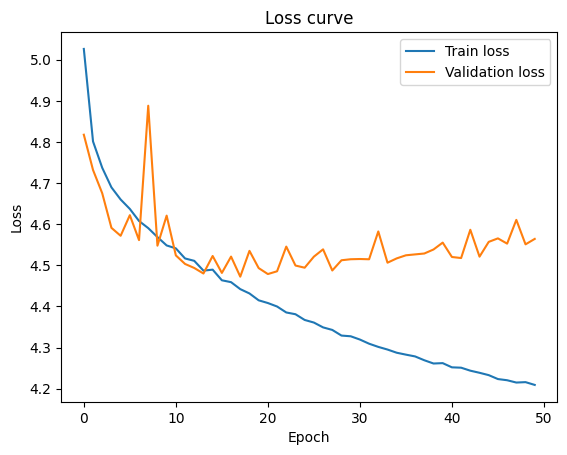

In [ ]:
plt.figure()
plt.plot(tr_losses, label='Train loss')
plt.plot(val_losses, label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss curve')
plt.legend()
plt.show()


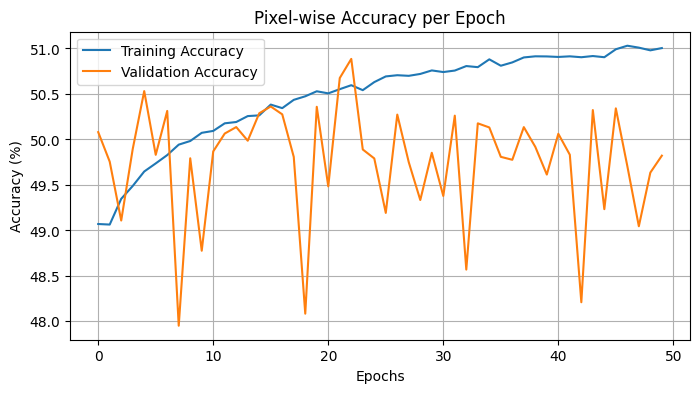

In [ ]:

plt.figure(figsize=(8, 4))
plt.plot(tr_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Pixel-wise Accuracy per Epoch')
plt.ylabel('Accuracy (%)')
plt.xlabel('Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
torch.save(net.state_dict(), './color_net_best.pth')


In [ ]:
# 初始化模型结构
net = TinyColorizationNet().to(device)

# 加载保存的参数
net.load_state_dict(torch.load('./color_net_best.pth'))
net.eval()  # 推理模式


C:\Users\Ting Ting\AppData\Local\Temp\ipykernel_21300\277264055.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load('./color_net_best.pth'))


TinyColorizationNet(
  (conv1_1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1_1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv1_2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1_2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2_1): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (bn2_1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2_2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2_2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3_1): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (bn3_1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3_2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3_2): BatchNorm2d(64, eps=1e-05, momentum=0.1,

In [ ]:
import glob
import random
from PIL import Image
import numpy as np
from skimage.color import rgb2lab, lab2rgb
import torch

# 选取10张图片
img_paths = glob.glob(r'C:\Users\Ting Ting\XIA\DATA\content\coco_dataset\test2014\*.jpg')
selected_paths = random.sample(img_paths, 10)


In [ ]:
# results = []

# for path in selected_paths:
#     # 1. 读取图片
#     img = Image.open(path).convert("RGB")
#     img = img.resize((32, 32))  # 训练用的是32x32就resize到32x32

#     # 2. 转LAB
#     img_np = np.array(img)
#     lab = rgb2lab(img_np)
#     L = lab[:, :, 0:1] - 50.0   # shape: (32,32,1)
#     L_tensor = torch.from_numpy(L).permute(2,0,1).unsqueeze(0).float().to(device)  # (1,1,32,32)

#     # 3. 用模型推理ab
#     with torch.no_grad():
#         logits = net(L_tensor)   # (1,313,8,8)
#         logits_up = F.interpolate(logits, size=(32, 32), mode="bilinear", align_corners=False)  # (1,313,32,32)
#         ab_idx = logits_up.argmax(1)  # (1,32,32)
#         ab_idx_np = ab_idx.squeeze(0).cpu().numpy()  # (32,32)
#         ab_pred = ab_bins_cpu[ab_idx_np]  # (32,32,2)

#         # 查表还原ab
#         ab_pred = ab_bins_cpu[ab_idx_np]  # (H,W,2)
#         # 合成LAB
#         # 合成LAB
#         L_original = (L + 50.0).squeeze().reshape(32, 32, 1)  # (32,32,1)
#         lab_pred = np.concatenate([L_original, ab_pred], axis=-1)  # (32,32,3)

#         grey = np.tile(L_original, (1, 1, 3)).astype(np.uint8)  # 灰度三通道

#         # lab2rgb
#         color_pred = lab2rgb(lab_pred.astype(np.float64))
#         color_pred = (np.clip(color_pred, 0, 1) * 255).astype(np.uint8)

#     # 保存/显示真实彩色、灰度、预测彩色
#     results.append({
#         "original_color": img_np,  # (H,W,3) uint8
#         "grey":  grey,  # 可选：三通道灰度
#         "color_pred": color_pred,  # (H,W,3) uint8
#         "path": path
#     })


In [ ]:
results = []
for path in selected_paths:
    # ——— 1. 读原图并 resize ———
    img = Image.open(path).convert("RGB")
    img = img.resize((32, 32))  # 训练用的是32x32就resize到32x32

    # 2. 转LAB
    img_np = np.array(img)
    lab = rgb2lab(img_np)
    L = lab[:, :, 0:1] - 50.0   # shape: (32,32,1)
    L_t = torch.from_numpy(L).permute(2,0,1).unsqueeze(0).float().to(device)  # (1,1,32,32)

    # ——— 3. 构造输入 tensor ———
    # L_t = torch.from_numpy(L)                  # (32,32,1)
    # L_t = L_t.permute(2,0,1).unsqueeze(0).to(device)  # (1,1,32,32)

    # ——— 4. 网络推理拿 ab 回归结果 ———
    with torch.no_grad():
        ab_pred = net(L_t)  # 假设 net 输出 (1,2,8,8)
        ab_pred = F.interpolate(ab_pred,
                               size=(32,32),
                               mode='bilinear',
                               align_corners=False)     # (1,2,32,32)
        ab = ab_pred[0].permute(1,2,0).cpu().numpy()  # (32,32,2)

    # ——— 5. 合成 Lab -> RGB ———
    L_orig = (L + 50.0).squeeze(-1)         # (32,32) 恢复到 [0,100]
    lab_pred = np.concatenate([L_orig[:,:,None], ab], axis=-1)  # (32,32,3)
    color = lab2rgb(lab_pred)              # float in [0,1]
    color = (color*255).astype(np.uint8)    # uint8

    # ——— 6. 准备三通道灰度图用于显示 ———
    #    这里直接用 L_orig 拉伸到 0–255
    L_original = (L + 50.0).squeeze().reshape(32, 32, 1)  # (32,32,1)
    grey = np.tile(L_original, (1, 1, 3)).astype(np.uint8)  # 灰度三通道
    # ——— 7. 存到结果列表 ———
    results.append({
        "original": img_np,  # 原彩色
        "grey":     grey,   # 三通道灰度
        "color":    color,   # 网络上色结果
        "path":     path
    })

In [ ]:
print("L_original shape:", L_orig.shape)
print("ab_pred shape:", ab_pred.shape)


L_original shape: (32, 32)
ab_pred shape: torch.Size([1, 2, 32, 32])


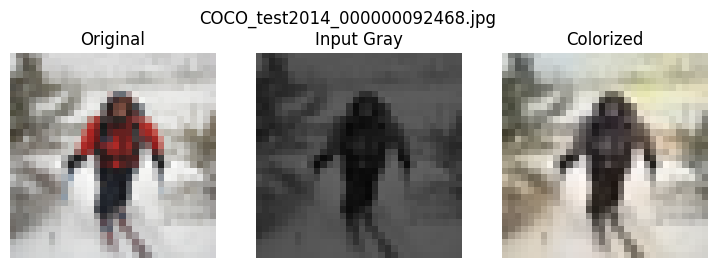

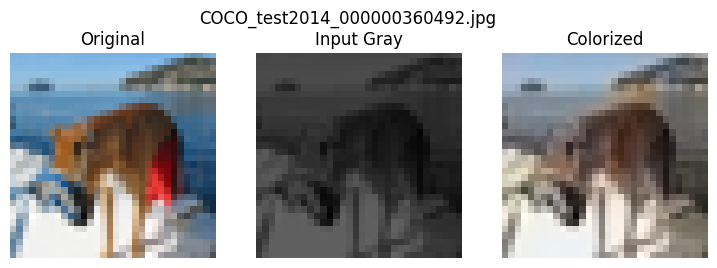

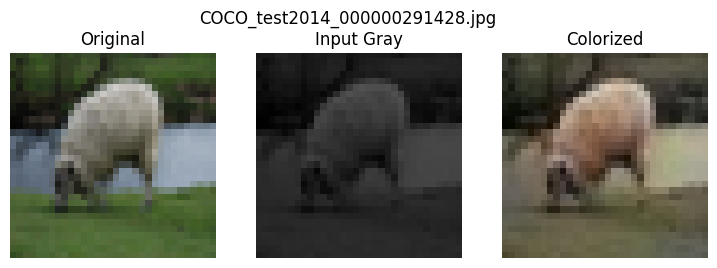

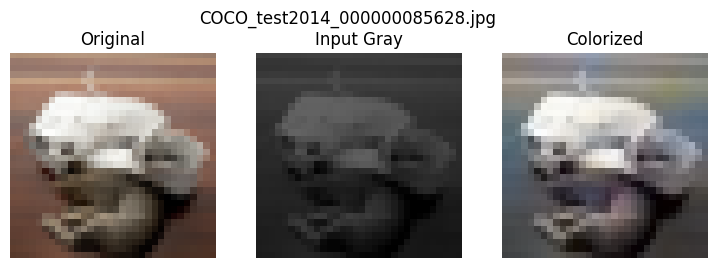

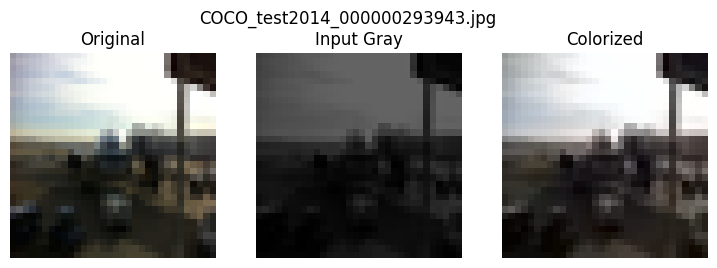

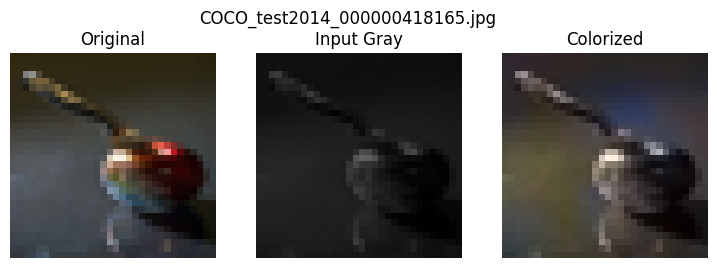

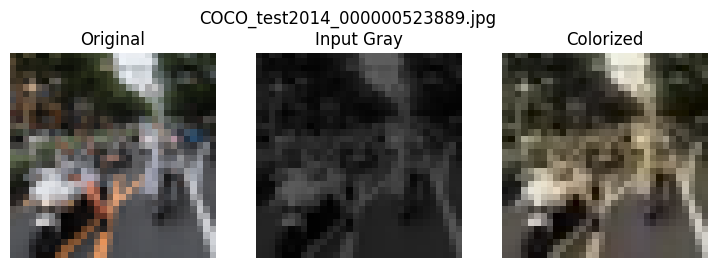

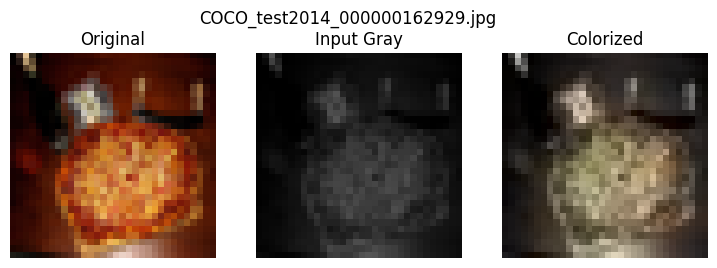

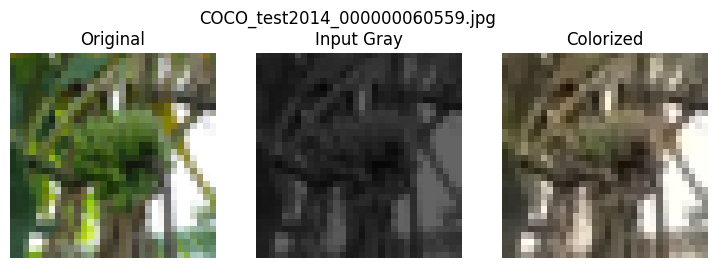

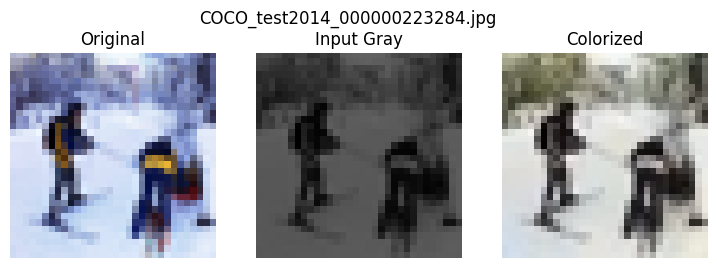

In [ ]:
import os
import matplotlib.pyplot as plt

save_dir = r"C:\Users\Ting Ting\XIA\year two\machine learning\CNN_project\colorization_results2"
os.makedirs(save_dir, exist_ok=True)

for i, res in enumerate(results):
    img_np = res["original"]
    gray  = res["grey"]
    color  = res["color"]
    path   = res["path"]

    plt.figure(figsize=(9,3))

    plt.subplot(1,3,1)
    plt.title("Original")
    plt.imshow(img_np)
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.title("Input Gray")
    plt.imshow(gray, cmap="gray")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.title("Colorized")
    plt.imshow(color)
    plt.axis("off")

    fname = os.path.basename(path)
    plt.suptitle(fname)

    # 如果你想保存结果，就取消下面两行的注释
    out_name = fname.replace(".jpg", f"_result_{i}.png")
    plt.savefig(os.path.join(save_dir, out_name), bbox_inches='tight', dpi=200)

    plt.show()


In [ ]:
# import matplotlib.pyplot as plt

# save_dir = r"C:\Users\Ting Ting\XIA\year two\machine learning\CNN_project\colorization_results"  # 你想保存的文件夹
# os.makedirs(save_dir, exist_ok=True)  # 自动创建目录

# for i, res in enumerate(results):
#     plt.figure(figsize=(12,3))
#     plt.subplot(1,3,1)
#     plt.title('Original')
#     plt.imshow(res["original_color"])
#     plt.axis('off')
#     plt.subplot(1,3,2)
#     plt.title('Input Gray')
#     plt.imshow(res["grey"], cmap='gray')
#     plt.axis('off')
#     plt.subplot(1,3,3)
#     plt.title('Colorized')
#     plt.imshow(res["color_pred"])
#     plt.axis('off')
#     plt.suptitle(res["path"].split("\\")[-1])

#     filename = res["path"].split("\\")[-1].replace(".jpg", f"_result_{i}.png")
#     plt.savefig(os.path.join(save_dir, filename), bbox_inches='tight', dpi=200)
#     plt.show()


In [ ]:
# from torch.utils.data import Dataset
# from torchvision import datasets, transforms
# import numpy as np
# from skimage.color import rgb2lab
# import torch

# class ColorizationDataset(Dataset):
#     def __init__(self, dataset):
#         self.dataset = dataset
#         self.resize = transforms.Resize((224, 224))  # 跟论文一致
#     def __len__(self):
#         return len(self.dataset)
#     def __getitem__(self, idx):
#         img, _ = self.dataset[idx]
#         print("getitem idx", idx, "type(img)", type(img))  # <--- 看下类型
#         img = self.resize(img)
#         print("after resize, type(img)", type(img))        # <--- 看下类型
#         img = np.array(img)  # (H, W, 3), 0-255
#         print("after np.array, type(img)", type(img))      # <--- 看下类型
#         lab = rgb2lab(img)   # (H, W, 3)
#         L = lab[:, :, 0:1] - 50.0          # (H, W, 1), mean-center
#         ab = lab[:, :, 1:]                 # (H, W, 2)
#         L = torch.from_numpy(L).permute(2, 0, 1).float()
#         ab = torch.from_numpy(ab).permute(2, 0, 1).float()
#         return L, ab

# # 重新声明 trainset 保证 transform=None
# trainset = datasets.CIFAR10(
#     root=r'C:\Users\Ting Ting\XIA\DATA\CIFAR10',
#     train=True,
#     download=False,
#     transform=None
# )
# dataset = ColorizationDataset(trainset)

# from torch.utils.data import DataLoader
# trainloader = DataLoader(dataset, batch_size=8, shuffle=True, num_workers=0)
# for L, ab in trainloader:
#     print("Batch loaded: L.shape", L.shape, "ab.shape", ab.shape)
#     break


In [ ]:
# ab_tensor = torch.randn(16, 2, 112, 112).to(device)
# ab_bins = np.load(r"C:\Users\Ting Ting\XIA\year two\machine learning\CNN_project\pts_in_hull.npy")  # shape: (313, 2)
# ab_bins = torch.from_numpy(ab_bins).float().to(device)  # (313,2)
# import time
# t0 = time.time()
# target = ab2bin_idx_batch(ab_tensor, ab_bins)
# t1 = time.time()
# print('ab2bin_idx_batch for one batch:', t1-t0, 'seconds')

In [ ]:
# dataset = ColorizationDataset(trainset) # test the time for ColorizationDataset
# for i in range(10):
#     L, ab = dataset[i]
